<a href="https://colab.research.google.com/github/jessrat/MachineLearning_Unidad3/blob/main/IA_y_Machine_Learning_Unidad3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# cargar archivos excel
from google.colab import files
import pandas as pd
import io

uploaded = files.upload()

# cargamos el dataset
file_name = next(iter(uploaded))
df = pd.read_excel(io.BytesIO(uploaded[file_name]))

# muestra las primeras 5 lineas
display(df.head())

Saving S8_DATASET_TAREA_SET_A_INTAA1301.xlsx to S8_DATASET_TAREA_SET_A_INTAA1301.xlsx


,edad_paciente,dias_espera,ausencias_previas,consultas_ultimo_anio,distancia_km,canal_confirmacion,asistio_cita
0,55,4,7,18,19,SMS,1
1,22,39,6,14,40,SMS,1
2,33,11,5,3,19,SMS,1
3,70,9,0,5,22,Llamada,1
4,69,9,8,13,46,Llamada,1


In [ ]:
# ----------------------------------------------------
# PREGUNTA 1 - Red Neuronal para Hospital San Gabriel
# ----------------------------------------------------

# Instalar librerías
!pip install -q tensorflow openpyxl scikit-learn

# Importar librerías
from google.colab import files
import pandas as pd
import numpy as np
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

print("\nColumnas:")
print(df.columns.tolist())

# 2. Separar variables predictoras y variable objetivo
X = df.drop(columns=["asistio_cita"])
y = df["asistio_cita"]

# 3. Definir variables numéricas y categóricas
variables_numericas = [
    "edad_paciente",
    "dias_espera",
    "ausencias_previas",
    "consultas_ultimo_anio",
    "distancia_km"
]
variables_categoricas = [   "canal_confirmacion"]
# 4. Separar datos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.20,random_state=42,    stratify=y)

# 5. Crear preprocesador
preprocesador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            StandardScaler(),
            variables_numericas
        ),
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            variables_categoricas
        )
    ]
)

# 6. Ajustar el preprocesador SOLO con entrenamiento
X_train_procesado = preprocesador.fit_transform(X_train)
X_test_procesado = preprocesador.transform(X_test)

# 7. Convertir a matriz NumPy si fuera necesario

if hasattr(X_train_procesado, "toarray"):
    X_train_procesado = X_train_procesado.toarray()

if hasattr(X_test_procesado, "toarray"):
    X_test_procesado = X_test_procesado.toarray()


print("\nCantidad de variables después del procesamiento:")
print(X_train_procesado.shape[1])

print("Registros de entrenamiento:", X_train_procesado.shape[0])
print("Registros de prueba:", X_test_procesado.shape[0])

# 8. Crear modelo de red neuronal
modelo = tf.keras.Sequential([

    tf.keras.layers.Input(
        shape=(X_train_procesado.shape[1],)
    ),

    tf.keras.layers.Dense(
        16,
        activation="relu"
    ),

    tf.keras.layers.Dropout(
        0.20
    ),

    tf.keras.layers.Dense(
        8,
        activation="relu"
    ),

    tf.keras.layers.Dropout(
        0.20
    ),

    tf.keras.layers.Dense(
        1,
        activation="sigmoid"
    )
])

# 9. Compilar modelo
modelo.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 10. Mostrar arquitectura
print("\nArquitectura de la red neuronal:")

modelo.summary()


Columnas:
['edad_paciente', 'dias_espera', 'ausencias_previas', 'consultas_ultimo_anio', 'distancia_km', 'canal_confirmacion', 'asistio_cita']

Cantidad de variables después del procesamiento:
8
Registros de entrenamiento: 120
Registros de prueba: 30

Arquitectura de la red neuronal:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.4639 - loss: 0.7301 - val_accuracy: 0.5652 - val_loss: 0.6747
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5361 - loss: 0.6967 - val_accuracy: 0.5652 - val_loss: 0.6637
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6186 - loss: 0.6792 - val_accuracy: 0.5652 - val_loss: 0.6548
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5464 - loss: 0.6846 - val_accuracy: 0.6087 - val_loss: 0.6477
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6701 - loss: 0.6587 - val_accuracy: 0.6957 - val_loss: 0.6400
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6392 - loss: 0.6482 - val_accuracy: 0.7391 - val_loss: 0.6322
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6907 - loss: 0.6235 - val_accuracy: 0.7391 - val_loss: 0.6256
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6804 - loss: 0.6254 - val_accuracy: 0.7391 - val_loss:

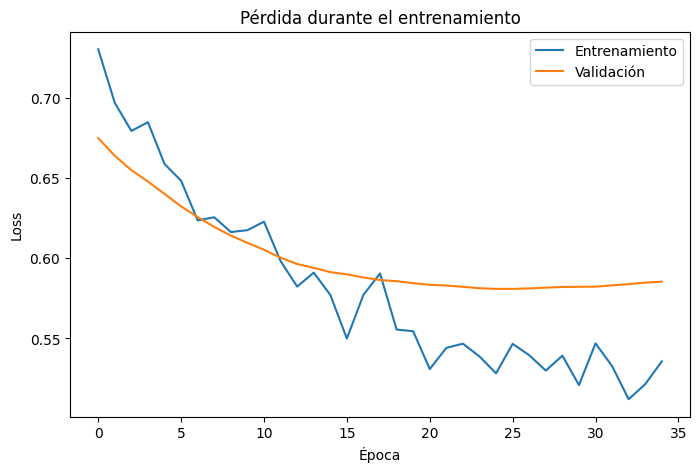

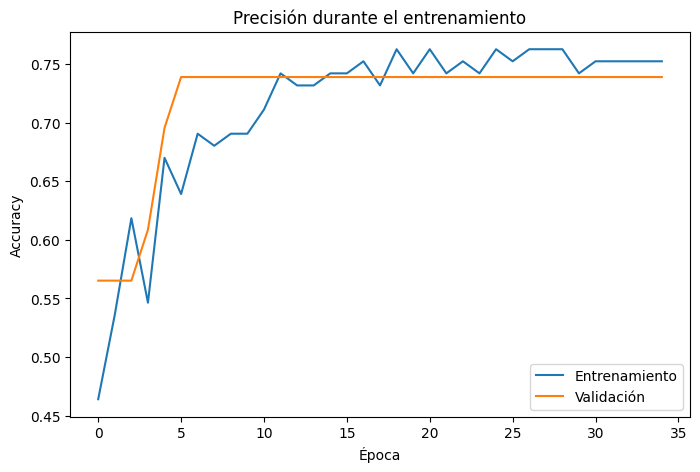

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step

MÉTRICAS DEL MODELO
Accuracy : 0.7000
Precision: 0.7241
Recall   : 0.9545
F1-score : 0.8235
AUC      : 0.8011

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

  No asistió       0.00      0.00      0.00         8
     Asistió       0.72      0.95      0.82        22

    accuracy                           0.70        30
   macro avg       0.36      0.48      0.41        30
weighted avg       0.53      0.70      0.60        30


MATRIZ DE CONFUSIÓN
[[ 0  8]
 [ 1 21]]


In [ ]:
# ---------------------------------------------------------
# PREGUNTA 2 - ENTRENAMIENTO Y EVALUACIÓN DEL MODELO
# ---------------------------------------------------------

import numpy as np
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt

# 1. Separar entrenamiento y validación
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_procesado,
    y_train,
    test_size=0.1875,
    random_state=42,
    stratify=y_train
)

# 2. Convertir datos al tipo numérico float32
X_train_final = np.asarray(X_train_final, dtype=np.float32)
X_val = np.asarray(X_val, dtype=np.float32)

X_test_procesado = np.asarray(
    X_test_procesado,
    dtype=np.float32
)

y_train_final = np.asarray(
    y_train_final,
    dtype=np.float32
)

y_val = np.asarray(
    y_val,
    dtype=np.float32
)

y_test = np.asarray(
    y_test,
    dtype=np.float32
)

# 3. Crear nuevamente el modelo
modelo = tf.keras.Sequential([

    tf.keras.layers.Input(
        shape=(X_train_final.shape[1],)
    ),

    tf.keras.layers.Dense(
        16,
        activation="relu"
    ),

    tf.keras.layers.Dropout(
        0.20
    ),

    tf.keras.layers.Dense(
        8,
        activation="relu"
    ),

    tf.keras.layers.Dropout(
        0.20
    ),

    tf.keras.layers.Dense(
        1,
        activation="sigmoid"
    )
])

# 4. Compilar modelo
modelo.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 5. Early Stopping
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# 6. Entrenamiento
historial = modelo.fit(
    X_train_final,
    y_train_final,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)

# 7. Gráfico de pérdida
plt.figure(figsize=(8, 5))

plt.plot(
    historial.history["loss"],
    label="Entrenamiento"
)

plt.plot(
    historial.history["val_loss"],
    label="Validación"
)

plt.title("Pérdida durante el entrenamiento")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.show()



# 8. Gráfico de precisión
plt.figure(figsize=(8, 5))

plt.plot(
    historial.history["accuracy"],
    label="Entrenamiento"
)

plt.plot(
    historial.history["val_accuracy"],
    label="Validación"
)

plt.title("Precisión durante el entrenamiento")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


# ============================================================
# 9. Predicciones
# ============================================================

probabilidades = modelo.predict(
    X_test_procesado
).ravel()

predicciones = (
    probabilidades >= 0.6
).astype(int)



# 10. Métricas
accuracy = accuracy_score(
    y_test,
    predicciones
)

precision = precision_score(
    y_test,
    predicciones,
    zero_division=0
)

recall = recall_score(
    y_test,
    predicciones,
    zero_division=0
)

f1 = f1_score(
    y_test,
    predicciones,
    zero_division=0
)

auc = roc_auc_score(
    y_test,
    probabilidades
)


print("\n==============================")
print("MÉTRICAS DEL MODELO")
print("==============================")

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"AUC      : {auc:.4f}")

# 11. Reporte de clasificación
print("\n==============================")
print("REPORTE DE CLASIFICACIÓN")
print("==============================")

print(
    classification_report(
        y_test,
        predicciones,
        target_names=[
            "No asistió",
            "Asistió"
        ],
        zero_division=0
    )
)

# 12. Matriz de confusión
matriz = confusion_matrix(
    y_test,
    predicciones
)

print("\n==============================")
print("MATRIZ DE CONFUSIÓN")
print("==============================")

print(matriz)

In [ ]:
# ============================================================
# SCRIPT 3 - AGENTE INTELIGENTE DE SEGUIMIENTO
# ============================================================

import numpy as np
import pandas as pd


# 1. Crear agente inteligente
class AgenteSeguimiento:

    def __init__(
        self,
        modelo,
        umbral_inasistencia=0.60
    ):

        self.modelo = modelo
        self.umbral_inasistencia = umbral_inasistencia



    # Analizar paciente
    def analizar_paciente(self, datos_paciente):

        # Asegurar que los datos sean numéricos
        datos_paciente = np.asarray(
            datos_paciente,
            dtype=np.float32
        )

        # Obtener probabilidad de asistencia
        prob_asistencia = float(
            self.modelo.predict(
                datos_paciente,
                verbose=0
            )[0][0]
        )

        # Probabilidad de inasistencia
        prob_inasistencia = 1 - prob_asistencia

        # Clasificación de riesgo

        if prob_inasistencia >= 0.70:

            nivel_riesgo = "ALTO"

            accion = (
                "Contactar al paciente y solicitar "
                "confirmación de asistencia."
            )

        elif prob_inasistencia >= self.umbral_inasistencia:

            nivel_riesgo = "MEDIO"

            accion = (
                "Enviar recordatorio y realizar "
                "seguimiento de confirmación."
            )

        else:

            nivel_riesgo = "BAJO"

            accion = (
                "Mantener seguimiento normal "
                "de la cita."
            )



        # Resultado
        return {
            "probabilidad_asistencia": round(
                prob_asistencia,
                4
            ),

            "probabilidad_inasistencia": round(
                prob_inasistencia,
                4
            ),

            "nivel_riesgo": nivel_riesgo,

            "accion": accion
        }



# 2. Crear instancia del agente
agente = AgenteSeguimiento(
    modelo=modelo,
    umbral_inasistencia=0.40
)

# 3. Analizar pacientes del conjunto de prueba
resultados = []
for i in range(len(X_test_procesado)):

    resultado = agente.analizar_paciente(
        X_test_procesado[i:i+1]
    )

    resultado["paciente"] = i + 1
    resultados.append(resultado)

# 4. Crear tabla de resultados
df_resultados = pd.DataFrame(
    resultados
)


# Ordenar columnas

df_resultados = df_resultados[
    [
        "paciente",
        "probabilidad_asistencia",
        "probabilidad_inasistencia",
        "nivel_riesgo",
        "accion"
    ]
]



# 5. Mostrar resultados
print("\n==========================================")
print("RESULTADOS DEL AGENTE DE SEGUIMIENTO")
print("==========================================")
display(df_resultados)


# 6. Resumen de niveles de riesgo
print("\n==========================================")
print("RESUMEN DE RIESGO")
print("==========================================")

print(
    df_resultados["nivel_riesgo"]
    .value_counts()
)


RESULTADOS DEL AGENTE DE SEGUIMIENTO


,paciente,probabilidad_asistencia,probabilidad_inasistencia,nivel_riesgo,accion
0,1,0.7202,0.2798,BAJO,Mantener seguimiento normal de la cita.
1,2,0.8841,0.1159,BAJO,Mantener seguimiento normal de la cita.
2,3,0.7394,0.2606,BAJO,Mantener seguimiento normal de la cita.
3,4,0.8000,0.2000,BAJO,Mantener seguimiento normal de la cita.
4,5,0.7485,0.2515,BAJO,Mantener seguimiento normal de la cita.
5,6,0.7738,0.2262,BAJO,Mantener seguimiento normal de la cita.
6,7,0.6380,0.3620,BAJO,Mantener seguimiento normal de la cita.
7,8,0.7670,0.2330,BAJO,Mantener seguimiento normal de la cita.
8,9,0.5861,0.4139,MEDIO,Enviar recordatorio y realizar seguimiento de ...
9,10,0.8190,0.1810,BAJO,Mantener seguimiento normal de la cita.



RESUMEN DE RIESGO
nivel_riesgo
BAJO     29
MEDIO     1
Name: count, dtype: int64


In [ ]:
# ============================================================
# SCRIPT 4 - evaluación del agente
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Copiamos los resultados generados por el agente
evaluacion = df_resultados.copy()

# Agregamos el resultado real de asistencia
evaluacion["real_asistencia"] = np.asarray(y_test, dtype=int)

# Predicción del modelo usando el umbral 0.60
evaluacion["prediccion_asistencia"] = (
    evaluacion["probabilidad_asistencia"] >= 0.60
).astype(int)

# Indicamos si la predicción fue correcta
evaluacion["prediccion_correcta"] = (
    evaluacion["real_asistencia"] ==
    evaluacion["prediccion_asistencia"]
)

# Métricas de evaluación
accuracy = accuracy_score(
    evaluacion["real_asistencia"],
    evaluacion["prediccion_asistencia"]
)

precision = precision_score(
    evaluacion["real_asistencia"],
    evaluacion["prediccion_asistencia"],
    zero_division=0
)

recall = recall_score(
    evaluacion["real_asistencia"],
    evaluacion["prediccion_asistencia"],
    zero_division=0
)

f1 = f1_score(
    evaluacion["real_asistencia"],
    evaluacion["prediccion_asistencia"],
    zero_division=0
)

print("EVALUACIÓN DEL AGENTE")
print("---------------------")
print(f"Accuracy : {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall   : {recall:.2%}")
print(f"F1-Score : {f1:.2%}")

print("\nResultados por paciente:")
display(evaluacion[
    [
        "paciente",
        "probabilidad_asistencia",
        "probabilidad_inasistencia",
        "nivel_riesgo",
        "real_asistencia",
        "prediccion_asistencia",
        "prediccion_correcta"
    ]
])

EVALUACIÓN DEL AGENTE
---------------------
Accuracy : 70.00%
Precision: 72.41%
Recall   : 95.45%
F1-Score : 82.35%

Resultados por paciente:


,paciente,probabilidad_asistencia,probabilidad_inasistencia,nivel_riesgo,real_asistencia,prediccion_asistencia,prediccion_correcta
0,1,0.7202,0.2798,BAJO,1,1,True
1,2,0.8841,0.1159,BAJO,1,1,True
2,3,0.7394,0.2606,BAJO,1,1,True
3,4,0.8000,0.2000,BAJO,1,1,True
4,5,0.7485,0.2515,BAJO,0,1,False
5,6,0.7738,0.2262,BAJO,1,1,True
6,7,0.6380,0.3620,BAJO,0,1,False
7,8,0.7670,0.2330,BAJO,0,1,False
8,9,0.5861,0.4139,MEDIO,1,0,False
9,10,0.8190,0.1810,BAJO,1,1,True


  0%|          | 0/10 [00:00<?, ?it/s]

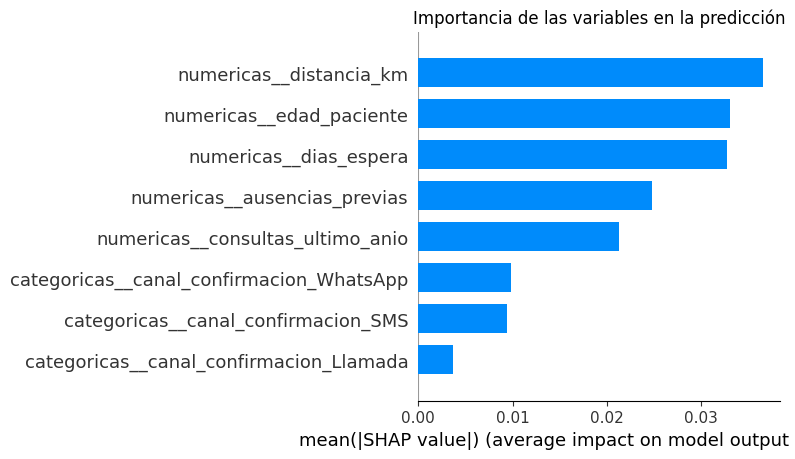

In [ ]:
# ==========================================================
# SCRIPT 5.1: INTERPRETABILIDAD DEL MODELO CON SHAP
# ==========================================================

!pip install -q shap

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

# Nombres de las variables después del preprocesamiento
nombres_variables = preprocesador.get_feature_names_out()

# Convertimos los datos procesados en DataFrames
X_entrenamiento_shap = pd.DataFrame(
    np.asarray(X_train_final, dtype=np.float32),
    columns=nombres_variables
)

X_prueba_shap = pd.DataFrame(
    np.asarray(X_test_procesado, dtype=np.float32),
    columns=nombres_variables
)

# Función para obtener la probabilidad de asistencia
def predecir_asistencia(datos):
    datos = np.asarray(datos, dtype=np.float32)
    return modelo.predict(datos, verbose=0).ravel()

# Seleccionamos una muestra para explicar las predicciones
datos_base = X_entrenamiento_shap.sample(
    n=min(20, len(X_entrenamiento_shap)),
    random_state=42
)

datos_explicar = X_prueba_shap.head(
    min(10, len(X_prueba_shap))
)

# Creamos el explicador SHAP
explicador = shap.KernelExplainer(
    predecir_asistencia,
    datos_base
)

# Calculamos la contribución de cada variable
valores_shap = explicador.shap_values(
    datos_explicar,
    nsamples=100
)

# Adaptamos el resultado para generar el gráfico
if isinstance(valores_shap, list):
    valores_shap = valores_shap[0]

valores_shap = np.asarray(valores_shap).squeeze()

# Gráfico de importancia global
shap.summary_plot(
    valores_shap,
    datos_explicar,
    feature_names=nombres_variables,
    plot_type="bar",
    show=False
)

plt.title("Importancia de las variables en la predicción")
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================================
# SCRIPT 5.2: MONITOREO Y MÉTRICAS DE IMPACTO
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Resultados reales del conjunto de prueba
y_real = np.asarray(y_test, dtype=int)

# Probabilidades generadas por el modelo
prob_asistencia = modelo.predict(
    X_test_procesado, verbose=0
).ravel()

# Se mantiene el umbral de 0.60
pred_asistencia = (
    prob_asistencia >= 0.60
).astype(int)

# Métricas generales
accuracy = accuracy_score(y_real, pred_asistencia)

precision = precision_score(
    y_real, pred_asistencia, zero_division=0
)

recall_asistencia = recall_score(
    y_real, pred_asistencia, pos_label=1,
    zero_division=0
)

f1 = f1_score(
    y_real, pred_asistencia, zero_division=0
)

# Detección específica de inasistencias (clase 0)
recall_inasistencia = recall_score(
    y_real, pred_asistencia, pos_label=0,
    zero_division=0
)

matriz = confusion_matrix(
    y_real, pred_asistencia, labels=[0, 1]
)

# Línea base del conjunto de datos original
total_pacientes = len(df)
total_asistencias = int((df["asistio_cita"] == 1).sum())
total_inasistencias = int((df["asistio_cita"] == 0).sum())

tasa_base_inasistencia = (
    total_inasistencias / total_pacientes
) * 100

# Resultados observados en el conjunto de prueba
tasa_real_prueba = (
    np.sum(y_real == 0) / len(y_real)
) * 100

tasa_predicha_inasistencia = (
    np.sum(pred_asistencia == 0) / len(pred_asistencia)
) * 100

print("MONITOREO DEL MODELO")
print("--------------------")
print(f"Accuracy: {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall de asistencia: {recall_asistencia:.2%}")
print(f"Recall de inasistencia: {recall_inasistencia:.2%}")
print(f"F1-Score: {f1:.2%}")

print("\nMatriz de confusión:")
print(matriz)

print("\nLÍNEA BASE DEL HOSPITAL")
print("----------------------")
print(f"Total de pacientes: {total_pacientes}")
print(f"Asistencias: {total_asistencias}")
print(f"Inasistencias: {total_inasistencias}")
print(f"Tasa inicial de inasistencia: {tasa_base_inasistencia:.2f}%")

print("\nRESULTADOS DEL CONJUNTO DE PRUEBA")
print("---------------------------------")
print(f"Inasistencia real: {tasa_real_prueba:.2f}%")
print(
    "Inasistencia predicha por el modelo: "
    f"{tasa_predicha_inasistencia:.2f}%"
)

# Indicadores para el seguimiento futuro
indicadores = pd.DataFrame({
    "Indicador": [
        "Tasa de inasistencia",
        "Citas recuperadas",
        "Uso de la agenda médica",
        "Tiempo de seguimiento"
    ],
    "Cómo medirlo": [
        "Comparar las inasistencias antes y después",
        "Contar las citas recuperadas tras el contacto",
        "Medir las horas médicas efectivamente utilizadas",
        "Medir el tiempo entre la alerta y el contacto"
    ]
})

print("\nINDICADORES PARA EVALUAR EL IMPACTO")
display(indicadores)

MONITOREO DEL MODELO
--------------------
Accuracy: 70.00%
Precision: 72.41%
Recall de asistencia: 95.45%
Recall de inasistencia: 0.00%
F1-Score: 82.35%

Matriz de confusión:
[[ 0  8]
 [ 1 21]]

LÍNEA BASE DEL HOSPITAL
----------------------
Total de pacientes: 150
Asistencias: 112
Inasistencias: 38
Tasa inicial de inasistencia: 25.33%

RESULTADOS DEL CONJUNTO DE PRUEBA
---------------------------------
Inasistencia real: 26.67%
Inasistencia predicha por el modelo: 3.33%

INDICADORES PARA EVALUAR EL IMPACTO


,Indicador,Cómo medirlo
0,Tasa de inasistencia,Comparar las inasistencias antes y después
1,Citas recuperadas,Contar las citas recuperadas tras el contacto
2,Uso de la agenda médica,Medir las horas médicas efectivamente utilizadas
3,Tiempo de seguimiento,Medir el tiempo entre la alerta y el contacto
